<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [OR-Tools Optimization](https://github.com/Query-farm/vgi-ortools)

Compute optimal assignments, vehicle routes, schedules, network flows and packings, or solve constraint models, with Google OR-Tools.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-ortools/blob/main/notebooks/02_shipping_cost_and_capacity.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-ortools/blob/main/notebooks/README.md)


## 02 · A cheap shipment is not a capacity plan

**How much does the requested shipment cost, and how much more could this network carry?** Five directed arcs connect a synthetic source (0), two transfer nodes (1, 2), and a destination (3). Every flow unit is one indivisible crate in one planning period; every arc has an integer crate capacity and an integer cost per crate in illustrative cost units (CU). There are no transit times, losses, fixed charges or uncertainty.

We will solve a fixed-volume minimum-cost shipment, then a maximum-throughput problem on the same capacities. Both are real OR-Tools calls through SQL. A saturated arc in one returned flow is not by itself a proof that expanding it improves capacity.

### Choose the requested shipment

`SHIP_UNITS` accepts integers **1–17 crates**; default **12**, experiment **17**. These bounds describe the authored network, not arbitrary shipping data. Change the parameter and restart/run all. Capacities and prices stay fixed; only supply and demand change.

In [1]:
SHIP_UNITS = 12

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.23":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.23"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime

check_runtime()

In [3]:
if type(SHIP_UNITS) is not int or not 1 <= SHIP_UNITS <= 17:
    raise ValueError("SHIP_UNITS must be an integer from 1 to 17 crates.")
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme

theme()
session = connect(globals())
COLORS = {"A": "#287E69", "B": "#357B9D", "C": "#B16B39"}

SOURCE = "Source: authored five-arc network · released OR-Tools worker v0.4.0 · crates per period / illustrative CU"

### Connect to the released optimizer

The literal `uvx` command launches published **v0.4.0** in its own Python 3.13 environment. The notebook kernel installs the shared base package; the local environment adds `[runner]`. No local worker checkout, SDK override or direct Python optimizer is needed. First use needs Git, package and VGI extension downloads; the optimization itself is local CPU work. The shared connection uses an empty temporary SQL secret directory and disables persisted secrets.

`solver_info` records the actual OR-Tools version and JSON dialect. Source is release-pinned; transitive packages follow the release constraints, including OR-Tools 9.15. A status applies to the solver family: these examples use exact flow/knapsack and single-threaded CP-SAT, not routing-library heuristics.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ortools' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-ortools@v0.4.0 vgi-ortools');
SELECT component, version FROM ortools.main.solver_info ORDER BY component;

,component,version
0,cp_sat,9.15.6755
1,dialect,1
2,glop,9.15.6755
3,ortools,9.15.6755
4,pdlp,9.15.6755
5,worker,0.4.0


### Preserve the network before solving

The arc list is derived from this worker's composed flow example, with explicit units and labels added here. Costs apply on every traversed arc: a crate traveling two arcs pays twice. SQL creates the scalar matrices; a folded transfer cell passes their exact integer list text to visible table-function calls because those arguments cannot be correlated subqueries.

In [5]:
%%sql matrices <<
CREATE TABLE arcs AS
SELECT * FROM (VALUES (0,1,10,2),(0,2,8,5),(1,2,6,1),(1,3,5,4),(2,3,12,2))
AS a(tail,head,capacity_crates,unit_cost_cu);
SELECT to_json(list([tail,head,capacity_crates,unit_cost_cu]::BIGINT[] ORDER BY tail,head)) AS cost_arcs,
       to_json(list([tail,head,capacity_crates]::BIGINT[] ORDER BY tail,head)) AS capacity_arcs
FROM arcs;

In [6]:
cost_arcs_sql = str(matrices.cost_arcs.iloc[0])
capacity_arcs_sql = str(matrices.capacity_arcs.iloc[0])

### Price the requested crates

Positive supply at node 0 and equal negative supply at node 3 force the requested shipment. `min_cost_flow` returns only arcs with positive flow. Materialize that call once, then left-join to the complete network so unused arcs remain visible as zero **after confirming an OPTIMAL result**. A no-solution status row must not be converted to a zero-cost shipment.

In [7]:
%%sql shipment_status <<
CREATE TABLE cost_rows AS
SELECT * FROM ortools.main.min_cost_flow(arcs := {{ cost_arcs_sql }}::BIGINT[][],
    supplies := [[0,{{ SHIP_UNITS }}],[3,-{{ SHIP_UNITS }}]]::BIGINT[][]);
SELECT min(status) AS status,count(*) AS returned_arcs,sum(cost) AS total_cost_cu FROM cost_rows;

In [8]:
display(shipment_status)
if set(shipment_status.status) != {"OPTIMAL"}:
    raise RuntimeError(
        "No optimal fixed-volume shipment: inspect the raw status rows before plotting."
    )
total_cost = int(shipment_status.total_cost_cu.iloc[0])
prose(
    f"Shipping **{SHIP_UNITS} crates** costs **{total_cost} CU** in this network. This is a minimum-cost proof for the fixed volume; it does not yet tell us the network's maximum volume."
)

,status,returned_arcs,total_cost_cu
0,OPTIMAL,5,68.0


Shipping **12 crates** costs **68 CU** in this network. This is a minimum-cost proof for the fixed volume; it does not yet tell us the network's maximum volume.

### Solve capacity separately, then reconcile the scalar shortcut

`max_flow` ignores prices and maximizes source-to-destination throughput. Its arc rows explain a feasible routing; `max_flow_value` returns only the optimal throughput for the same matrix. We use both to check their agreement and compute remaining shipment headroom. An unused arc is not missing data: successful flow functions omit zero-flow arcs.

In [9]:
%%sql capacity_summary <<
CREATE TABLE capacity_rows AS
SELECT * FROM ortools.main.max_flow(arcs := {{ capacity_arcs_sql }}::BIGINT[][],source := 0,sink := 3);
CREATE TABLE throughput AS
SELECT ortools.main.max_flow_value({{ capacity_arcs_sql }}::BIGINT[][],0,3) AS scalar_max_crates;
SELECT (SELECT min(status) FROM capacity_rows) AS status,scalar_max_crates,
       (SELECT sum(flow) FILTER(WHERE "from"=0) FROM capacity_rows) AS routed_max_crates,
       scalar_max_crates-{{ SHIP_UNITS }} AS headroom_crates FROM throughput;

In [10]:
display(capacity_summary)
assert capacity_summary.status.iloc[0] == "OPTIMAL"
maximum = int(capacity_summary.scalar_max_crates.iloc[0])
assert maximum == int(capacity_summary.routed_max_crates.iloc[0])
prose(
    f"Both interfaces give **{maximum} crates** of maximum throughput. The selected **{SHIP_UNITS}-crate** shipment leaves **{maximum - SHIP_UNITS} crates** of headroom. The source's outgoing capacities sum to 18, so that local sum alone overstates end-to-end capacity."
)

,status,scalar_max_crates,routed_max_crates,headroom_crates
0,OPTIMAL,17,17.0,5


Both interfaces give **17 crates** of maximum throughput. The selected **12-crate** shipment leaves **5 crates** of headroom. The source's outgoing capacities sum to 18, so that local sum alone overstates end-to-end capacity.

In [11]:
%%sql audit <<
CREATE TABLE arc_audit AS
SELECT a.*,coalesce(c.flow,0) AS shipment_flow,coalesce(c.cost,0) AS shipment_cost,
       coalesce(m.flow,0) AS maximum_flow
FROM arcs a LEFT JOIN cost_rows c ON a.tail=c."from" AND a.head=c."to"
LEFT JOIN capacity_rows m ON a.tail=m."from" AND a.head=m."to";
SELECT * FROM arc_audit ORDER BY tail,head;

,tail,head,capacity_crates,unit_cost_cu,shipment_flow,shipment_cost,maximum_flow
0,0,1,10,2,10,20,9
1,0,2,8,5,2,10,8
2,1,2,6,1,6,6,4
3,1,3,5,4,4,16,5
4,2,3,12,2,8,16,12


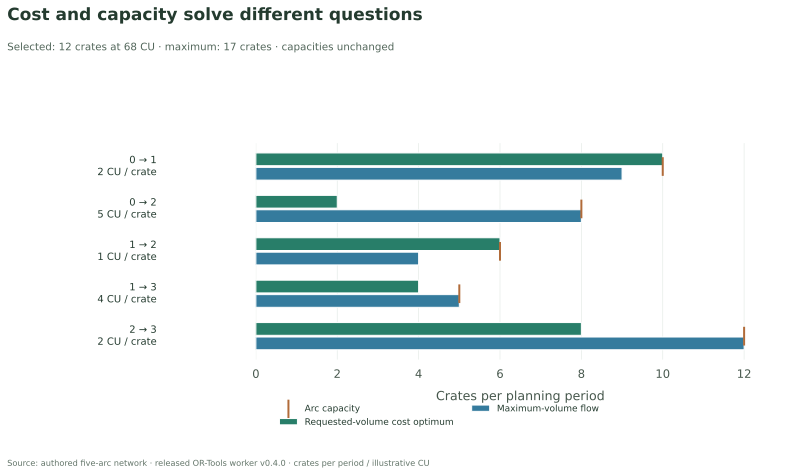

In [12]:
display(audit)
fig, (labels, ax) = plt.subplots(
    1, 2, figsize=(12, 7), sharey=True, gridspec_kw={"width_ratios": [1, 4]}
)
y = np.arange(len(audit))
for i, r in enumerate(audit.itertuples()):
    labels.text(
        1,
        i,
        f"{r.tail} → {r.head}\n{r.unit_cost_cu} CU / crate",
        ha="right",
        va="center",
        fontsize=10,
    )
labels.axis("off")
labels.set_xlim(0, 1)
ax.barh(
    y - 0.17,
    audit.shipment_flow,
    height=0.30,
    color="#287E69",
    label="Requested-volume cost optimum",
)
ax.barh(y + 0.17, audit.maximum_flow, height=0.30, color="#357B9D", label="Maximum-volume flow")
ax.scatter(
    audit.capacity_crates, y, marker="|", s=350, color="#B16B39", linewidth=2, label="Arc capacity"
)
ax.set(
    yticks=y,
    yticklabels=[""] * len(y),
    xlabel="Crates per planning period",
    xlim=(0, max(audit.capacity_crates) + 1),
)
ax.invert_yaxis()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x")
fig.legend(loc="lower center", bbox_to_anchor=(0.57, 0.12), ncol=2, fontsize=9)
finish(
    fig,
    "Cost and capacity solve different questions",
    f"Selected: {SHIP_UNITS} crates at {total_cost} CU · maximum: {maximum} crates · capacities unchanged",
    SOURCE,
    name=f"flows-{SHIP_UNITS}",
)

### Follow the cost across arcs

Arc costs sum to the shipment bill; arc flow counts do **not** sum to the number of crates delivered because transferred crates traverse multiple arcs. The next chart shows where the selected bill is incurred. A zero bar means an unused arc under this optimal routing, not an absent quote.

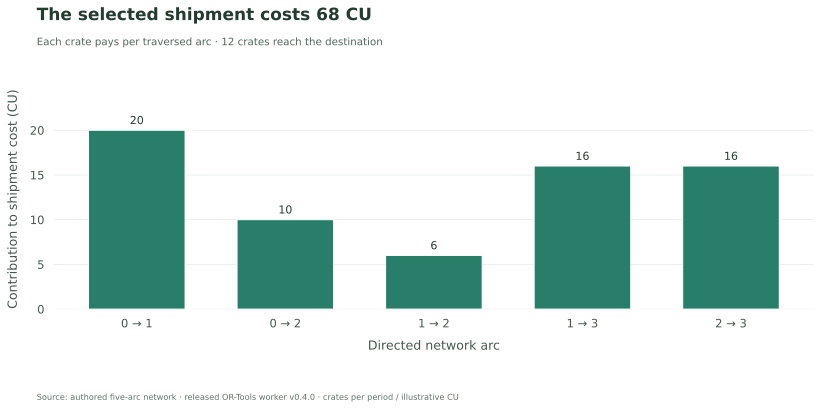

In [13]:
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(audit))
values = audit.shipment_cost.to_numpy()
ax.bar(x, values, color="#287E69", width=0.65)
for i, value in enumerate(values):
    ax.text(i, value + 0.4, f"{value:g}", ha="center", va="bottom")
ax.set(
    xticks=x,
    xticklabels=[f"{r.tail} → {r.head}" for r in audit.itertuples()],
    xlabel="Directed network arc",
    ylabel="Contribution to shipment cost (CU)",
    ylim=(0, max(values) * 1.18 + 1),
)
ax.grid(axis="y")
ax.set_axisbelow(True)
assert int(sum(values)) == total_cost
finish(
    fig,
    f"The selected shipment costs {total_cost} CU",
    f"Each crate pays per traversed arc · {SHIP_UNITS} crates reach the destination",
    SOURCE,
    name=f"costs-{SHIP_UNITS}",
)

### Verify conservation and the infeasible boundary

Check capacities, cost arithmetic, and node balance for both returned flows. Then request one crate above the independently computed maximum. `INFEASIBLE` must remain a single NULL-data status row; it is not an empty successful flow. This boundary check stays fixed when the selected shipment changes.

In [14]:
%%sql checks <<
WITH balances AS (
 SELECT n.node,
   sum(CASE WHEN a.tail=n.node THEN a.shipment_flow ELSE 0 END)-sum(CASE WHEN a.head=n.node THEN a.shipment_flow ELSE 0 END) AS net,
   sum(CASE WHEN a.tail=n.node THEN a.maximum_flow ELSE 0 END)-sum(CASE WHEN a.head=n.node THEN a.maximum_flow ELSE 0 END) AS max_net
 FROM range(4) n(node) CROSS JOIN arc_audit a GROUP BY n.node
)
SELECT 'Capacity and nonnegativity' AS check_name,bool_and(shipment_flow BETWEEN 0 AND capacity_crates AND maximum_flow BETWEEN 0 AND capacity_crates) AS passed FROM arc_audit
UNION ALL SELECT 'Arc cost arithmetic',bool_and(shipment_cost=shipment_flow*unit_cost_cu) FROM arc_audit
UNION ALL SELECT 'Requested flow conservation',bool_and(net=CASE node WHEN 0 THEN {{ SHIP_UNITS }} WHEN 3 THEN -{{ SHIP_UNITS }} ELSE 0 END) FROM balances
UNION ALL SELECT 'Maximum flow conservation',bool_and(max_net=CASE node WHEN 0 THEN {{ maximum }} WHEN 3 THEN -{{ maximum }} ELSE 0 END) FROM balances
UNION ALL SELECT 'Returned arcs are unique',count(*)=count(DISTINCT ("from","to")) FROM cost_rows
UNION ALL SELECT 'Maximum scalar agrees',scalar_max_crates=(SELECT sum(flow) FROM capacity_rows WHERE "from"=0) FROM throughput;

In [15]:
display(checks)
assert checks.passed.all()

,check_name,passed
0,Capacity and nonnegativity,True
1,Arc cost arithmetic,True
2,Requested flow conservation,True
3,Maximum flow conservation,True
4,Returned arcs are unique,True
5,Maximum scalar agrees,True


In [16]:
%%sql impossible <<
CREATE TABLE impossible_rows AS
SELECT * FROM ortools.main.min_cost_flow(arcs := {{ cost_arcs_sql }}::BIGINT[][],
 supplies := [[0,{{ maximum+1 }}],[3,-{{ maximum+1 }}]]::BIGINT[][]);
SELECT * FROM impossible_rows;

In [17]:
display(impossible)
assert len(impossible) == 1 and impossible.status.iloc[0] == "INFEASIBLE"
assert impossible[["from", "to", "flow", "cost"]].isna().all().all()
prose(
    f"The **{maximum + 1}-crate** request is INFEASIBLE, with one explicit status row and no flow data. All six feasible-flow checks passed. The network supports the selected shipment, but has no modeled route for one crate above its maximum."
)

,from,to,flow,cost,status
0,<NA>,<NA>,<NA>,<NA>,INFEASIBLE


The **18-crate** request is INFEASIBLE, with one explicit status row and no flow data. All six feasible-flow checks passed. The network supports the selected shipment, but has no modeled route for one crate above its maximum.

### Experiment: use all available throughput

Change **`SHIP_UNITS = 12` to `17`**, restart/run all, and compare both charts. Predict whether the cost grows in direct proportion to crate count. Capacities, unit costs, maximum-flow solution and the 18-crate infeasibility check should stay fixed. The selected cost optimum may change its arc allocation. Reset to **12**.

This is re-optimization on one deterministic network. The difference between two total costs is not a universally valid marginal price, and unused capacity on one arc does not promise usable end-to-end headroom.

In [18]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-ortools](https://github.com/Query-farm/vgi-ortools)
